# BÁO CÁO PHẦN 2 - BÀI 2 (TRANG 37, 38): ONLINE RETAIL DATASET (UNITED KINGDOM)
## CÂU 3: Thống kê số dòng dữ liệu theo từng quốc gia
- Đếm số lượng giao dịch tương ứng với từng quốc gia (`Country`)
- Vẽ biểu đồ trực quan hóa số lượng giao dịch của các quốc gia
- Đưa ra nhận xét về thị trường chính của doanh nghiệp


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
--- TOP 10 QUỐC GIA CÓ SỐ LƯỢNG GIAO DỊCH NHIỀU NHẤT ---
Country
United Kingdom    487622
Germany             9042
France              8408
EIRE                7894
Spain               2485
Netherlands         2363
Belgium             2031
Switzerland         1967
Portugal            1501
Australia           1185
Name: count, dtype: int64

Tỷ lệ giao dịch tại United Kingdom: 91.55%


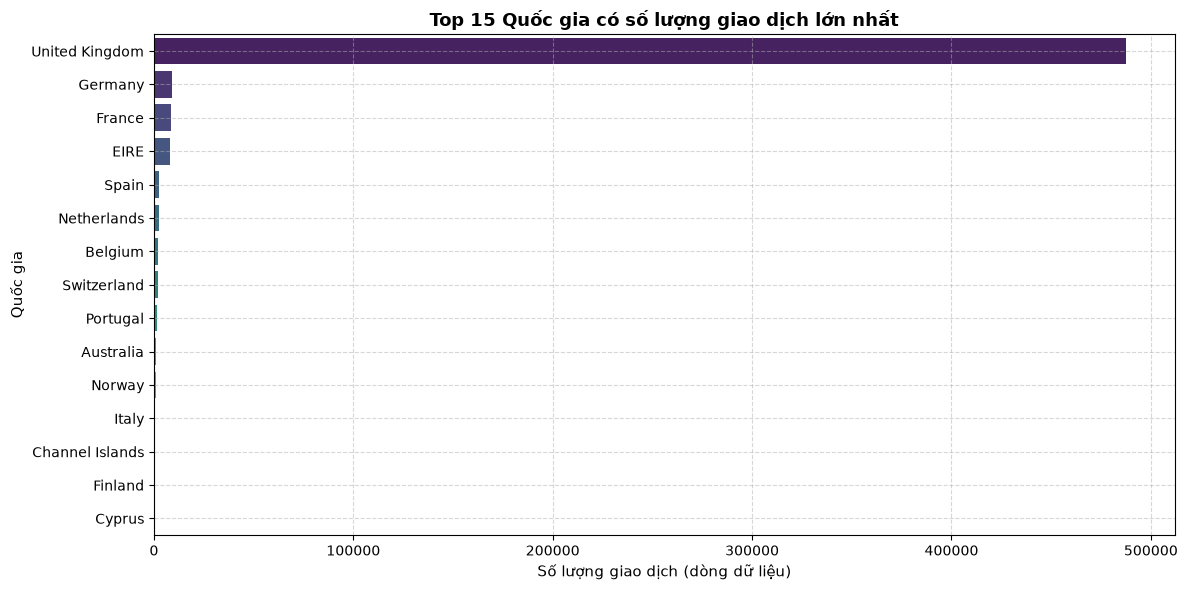

In [1]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)


df = load_online_retail()
df['Description'] = df['Description'].astype(str).str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df = df[~df['InvoiceNo'].str.contains('C')]

# Thống kê số lượng dòng dữ liệu theo quốc gia
country_counts = df['Country'].value_counts()
print("--- TOP 10 QUỐC GIA CÓ SỐ LƯỢNG GIAO DỊCH NHIỀU NHẤT ---")
print(country_counts.head(10))
print(f"\nTỷ lệ giao dịch tại United Kingdom: {round((country_counts['United Kingdom'] / len(df)) * 100, 2)}%")

# Vẽ biểu đồ barplot biểu diễn top 15 quốc gia
plt.figure(figsize=(12, 6))
top15_countries = country_counts.head(15)
sns.barplot(x=top15_countries.values, y=top15_countries.index, palette='viridis')
plt.title("Top 15 Quốc gia có số lượng giao dịch lớn nhất", fontsize=13, fontweight='bold')
plt.xlabel("Số lượng giao dịch (dòng dữ liệu)", fontsize=11)
plt.ylabel("Quốc gia", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Nhận xét Câu 3:
- Nước Anh (**United Kingdom**) chiếm tỷ trọng áp đảo tuyệt đối trong tập dữ liệu với 487.622 dòng giao dịch (chiếm **91.55%** tổng số dữ liệu).
- Các quốc gia Châu Âu khác xếp sau gồm có: Đức (Germany), Pháp (France), Ireland (EIRE), Tây Ban Nha (Spain), Hà Lan (Netherlands),... nhưng số lượng giao dịch ít hơn rất nhiều.
- Vì vậy, việc phân tách riêng từng quốc gia (đặc biệt là thị trường UK) để khai phá luật kết hợp là hoàn toàn chính xác nhằm tránh sự sai lệch do văn hóa tiêu dùng và chi phí vận chuyển khác nhau.
